# EJERCICIO 1: Optimización del uso de máquinas en una fábrica

Enunciado
Una fábrica tiene 5 máquinas disponibles para realizar 3 tipos de tareas: corte, ensamblado y pintura. Cada máquina puede hacer al menos una de estas tareas, pero con diferente eficiencia y consumo energético.

Tu objetivo es maximizar la eficiencia total de producción sin superar un límite de consumo energético diario.

Variables
* Genotipo: vector de asignaciones [M1_Tarea, M2_Tarea, ..., M5_Tarea]
* Fitness: suma ponderada de eficiencia total
* Restricción: consumo energético < 800 kWh/día

Experimentación
* Operadores de selección: torneo vs ruleta
* Cruce: 1 punto vs uniforme
* Mutación: cambio de tarea aleatorio
* Elitismo: 10% de mejores individuos conservados

Evaluaciones
* Fitness vs generación
* Diversidad poblacional (tareas únicas asignadas por generación)

In [ ]:
%pip install deap

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Solución utilizando librería DEAP
import random
import numpy as np
import matplotlib.pyplot as plt
from deap import base, creator, tools, algorithms

In [3]:
# Configuración del problema
NUM_MACHINES = 5
NUM_TASKS = 3
MAX_ENERGY = 800  # kWh

In [4]:
# Eficiencia y consumo de energía por tarea y máquina (ficticios)
efficiency_matrix = np.random.randint(60, 100, size=(NUM_MACHINES, NUM_TASKS))
energy_matrix = np.random.randint(100, 250, size=(NUM_MACHINES, NUM_TASKS))

In [5]:
# Configuración DEAP
creator.create("FitnessMax", base.Fitness, weights=(1.0,))
creator.create("Individual", list, fitness=creator.FitnessMax)

In [6]:
# Toolbox
toolbox = base.Toolbox()
toolbox.register("attr_task", random.randrange, NUM_TASKS)
toolbox.register("individual", tools.initRepeat, creator.Individual, toolbox.attr_task, n=NUM_MACHINES)
toolbox.register("population", tools.initRepeat, list, toolbox.individual)

def evalFactory(individual):
    total_eff = 0
    total_energy = 0
    for i, task in enumerate(individual):
        total_eff += efficiency_matrix[i][task]
        total_energy += energy_matrix[i][task]
    if total_energy > MAX_ENERGY:
        return 0.0,  # Penalización por sobreconsumo
    return total_eff,

toolbox.register("evaluate", evalFactory)
toolbox.register("mate", tools.cxOnePoint)
toolbox.register("mutate", tools.mutUniformInt, low=0, up=NUM_TASKS-1, indpb=0.2)
toolbox.register("select", tools.selTournament, tournsize=3)

In [7]:
# Ejecutar algoritmo
POP_SIZE = 50
NGEN = 50
CXPB = 0.7
MUTPB = 0.2

pop = toolbox.population(n=POP_SIZE)
hof = tools.HallOfFame(1)
stats = tools.Statistics(lambda ind: ind.fitness.values[0])
stats.register("avg", np.mean)
stats.register("max", np.max)
stats.register("min", np.min)

pop, log = algorithms.eaSimple(pop, toolbox, cxpb=CXPB, mutpb=MUTPB, ngen=NGEN,
                                stats=stats, halloffame=hof, verbose=True)

gen	nevals	avg  	max	min
0  	50    	71.58	427	0  
1  	30    	167.22	427	0  
2  	49    	243.76	438	0  
3  	38    	374.44	449	0  
4  	39    	421.42	449	0  
5  	38    	423.54	449	0  
6  	32    	440.3 	450	405
7  	41    	438.94	450	0  
8  	32    	431   	450	0  
9  	38    	412.5 	450	0  
10 	29    	438.08	450	0  
11 	37    	439.84	450	0  
12 	37    	440.56	450	0  
13 	34    	431.88	450	0  
14 	39    	421.52	450	0  
15 	38    	441   	450	0  
16 	30    	422.54	450	0  
17 	32    	412.9 	450	0  
18 	37    	404.98	450	0  
19 	45    	431.44	450	0  
20 	46    	420.92	450	0  
21 	37    	431.28	450	0  
22 	40    	394.92	450	0  
23 	36    	396   	450	0  
24 	38    	422.64	450	0  
25 	35    	404.04	450	0  
26 	35    	439.88	450	0  
27 	41    	439.46	450	0  
28 	39    	395.9 	450	0  
29 	38    	414   	450	0  
30 	40    	395.12	450	0  
31 	38    	431.9 	450	0  
32 	35    	412.18	450	0  
33 	41    	418.92	450	0  
34 	37    	423   	450	0  
35 	35    	410.72	450	0  
36 	43    	413.02	450	0  
37 	33    	414

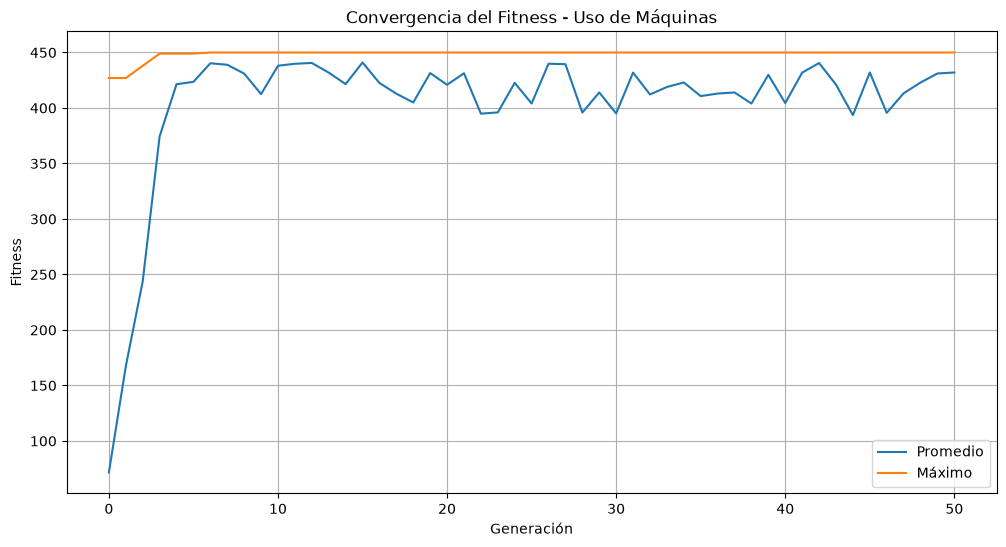

In [8]:
# Resultados y visualización
import pandas as pd
log_df = pd.DataFrame(log)
plt.figure(figsize=(12,6))
plt.plot(log_df['gen'], log_df['avg'], label='Promedio')
plt.plot(log_df['gen'], log_df['max'], label='Máximo')
plt.xlabel("Generación")
plt.ylabel("Fitness")
plt.title("Convergencia del Fitness - Uso de Máquinas")
plt.legend()
plt.grid(True)
plt.show()

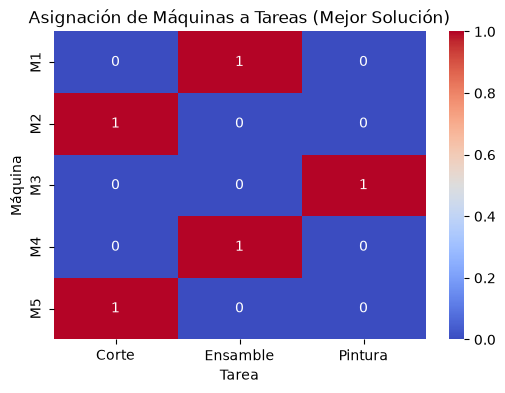

In [9]:
# Matriz de calor de la mejor solución
best = hof[0]
best_matrix = np.zeros((NUM_MACHINES, NUM_TASKS))
for i, task in enumerate(best):
    best_matrix[i][task] = 1

import seaborn as sns
plt.figure(figsize=(6, 4))
sns.heatmap(best_matrix, annot=True, cmap='coolwarm', xticklabels=["Corte", "Ensamble", "Pintura"],
            yticklabels=[f"M{i+1}" for i in range(NUM_MACHINES)])
plt.title("Asignación de Máquinas a Tareas (Mejor Solución)")
plt.xlabel("Tarea")
plt.ylabel("Máquina")
plt.show()